# Event footprints in the real record

An event in Geo-Disasters names one or more administrative units. If events are footprints, a region of random size placed somewhere on the map, the units one event names should be contiguous, more so than a random set of the same size from the same country. And if footprint size depends on the hazard, the reporting is not coarsened at random. This notebook checks both in the record behind 07's calibration.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import shapely
import skgstat

from scipy.sparse import coo_array
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

from climate_risk.data.gadm import load_units_in_country
from climate_risk.data.geo_disasters import GEO_DISASTERS_LAYER, geo_disasters_path
from climate_risk.data_functions.emdat_processing import load_emdat_events
from climate_risk.plotting import configure_plot_style

configure_plot_style()

SEED = 20261021

## The record

Every geocoded location with its polygon, kept at the event's finest level as in 07, joined to the EM-DAT climate-related events of 1990 to 2023 for their hazard type. A unit is identified by its GAUL code at its level.

In [2]:
DATA_DIR = Path("../../data").resolve()
FIRST_YEAR, LAST_YEAR = 1990, 2023
EQUAL_AREA_CRS = "EPSG:6933"

located = gpd.read_file(geo_disasters_path(DATA_DIR),
                        layer=GEO_DISASTERS_LAYER,
                        columns=["DisNo.", "ISO", "admin_level", "ADM1_CODE", "ADM2_CODE"]).to_crs(EQUAL_AREA_CRS)

located["admin_level"].value_counts()

admin_level
1    27265
2    17856
Name: count, dtype: int64

In [3]:
located["unit"] = np.where(located["admin_level"] == 2, located["ADM2_CODE"], located["ADM1_CODE"])
finest_level = located.groupby("DisNo.")["admin_level"].transform("max")
finest = located[located["admin_level"] == finest_level].drop_duplicates(["DisNo.", "unit"])

hazards = (
    load_emdat_events(DATA_DIR)
    .filter(pl.col("disaster_class").is_not_null())
    .with_columns(pl.col("DisNo.").str.slice(0, 4).cast(pl.Int32).alias("year"))
    .filter(pl.col("year").is_between(FIRST_YEAR, LAST_YEAR))
    .select("DisNo.", "Disaster Type")
    .to_pandas()
)
reports = finest.merge(hazards, on="DisNo.")

pd.Series({"located rows": len(located),
           "missing unit code": int(located["unit"].isna().sum()),
           "climate events geocoded": reports["DisNo."].nunique(),
           "events in more than one country": int((reports.groupby("DisNo.")["ISO"].nunique() > 1).sum()),
           "distinct units": reports.drop_duplicates(["admin_level", "unit"]).shape[0]})

located rows                       45121
missing unit code                      0
climate events geocoded             9121
events in more than one country       17
distinct units                     10458
dtype: int64

## Which units touch

Two units at the same level are neighbors when their polygons come within a kilometer of each other, which closes the slivers GAUL leaves along some shared borders. Only units the record ever names are in the graph, so an unnamed unit between two named ones breaks their adjacency.

In [4]:
NEIGHBOR_DISTANCE_M = 1_000.0

units = reports.drop_duplicates(["admin_level", "unit"])[["admin_level", "unit", "ISO", "geometry"]].reset_index(drop=True)
units["area_km2"] = units.area / 1e6
unit_index = pd.Series(units.index, index=pd.MultiIndex.from_frame(units[["admin_level", "unit"]]))


def neighbor_graph(units, distance):
    """Sparse symmetric adjacency between units at the same level whose polygons lie within ``distance``."""
    pairs = []
    for _, same_level in units.groupby("admin_level"):
        geometries = same_level.geometry.to_numpy()
        left, right = shapely.STRtree(geometries).query(geometries, predicate="dwithin", distance=distance)
        apart = left != right
        pairs.append(same_level.index.to_numpy()[np.column_stack([left[apart], right[apart]])])

    pairs = np.concatenate(pairs)

    return coo_array((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(len(units), len(units))).tocsr()


neighbors = neighbor_graph(units, NEIGHBOR_DISTANCE_M)
degree = np.asarray(neighbors.sum(axis=1)).ravel()

pd.DataFrame({level: pd.Series(degree[units["admin_level"] == level]).describe() for level in (1, 2)}).add_prefix("ADM").round(1)

,ADM1,ADM2
count,2845.00,7613.00
mean,4.70,3.30
std,2.30,2.70
min,0.00,0.00
25%,3.00,2.00
50%,5.00,3.00
75%,6.00,5.00
max,44.00,129.00


## Are an event's units contiguous?

For every event that names at least two units in a country, the number of connected pieces its units form. The null draws sets of the same size, uniformly, from the units the record names anywhere in the same country at the same level, so it shares the observed graph's gaps.

In [6]:
NULL_DRAWS = 100
SIZE_BINS = [2, 3, 4, 6, 11, np.inf]
SIZE_LABELS = ["2", "3", "4 to 5", "6 to 10", "over 10"]


def pieces(members):
    """Connected pieces among ``members`` in the neighbor graph."""
    return connected_components(neighbors[members][:, members], directed=False)[0]


reports["unit_index"] = unit_index.loc[list(zip(reports["admin_level"], reports["unit"], strict=True))].to_numpy()
pool = reports.groupby(["ISO", "admin_level"])["unit_index"].unique()

null_rng = np.random.default_rng(SEED)
rows = []
for (event, iso, level, hazard), group in tqdm(reports.groupby(["DisNo.", "ISO", "admin_level", "Disaster Type"])):
    members = group["unit_index"].to_numpy()
    if len(members) < 2:
        continue

    candidates = pool[(iso, level)]
    null_pieces = [pieces(null_rng.choice(candidates, size=len(members), replace=False)) for _ in range(NULL_DRAWS)]
    rows.append({"event": event,
                 "ISO": iso,
                 "level": f"ADM{level}",
                 "hazard": hazard,
                 "units": len(members),
                 "units in pool": len(candidates),
                 "pieces": pieces(members),
                 "null pieces": np.mean(null_pieces),
                 "null connected": np.mean(np.equal(null_pieces, 1))})

footprints = pd.DataFrame(rows)
footprints["size"] = pd.cut(footprints["units"], bins=SIZE_BINS, right=False, labels=SIZE_LABELS)

  0%|          | 0/9137 [00:00<?, ?it/s]

In [8]:
footprints["connected"] = footprints["pieces"] == 1

(
    footprints.groupby(["level", "size"], observed=True)
    .agg(events=("event", "size"),
         connected=("connected", "mean"),
         null_connected=("null connected", "mean"),
         pieces=("pieces", "mean"),
         null_pieces=("null pieces", "mean"),
         share_of_pool=("units", lambda units: (units / footprints.loc[units.index, "units in pool"]).median()))
    .rename(columns={"null_connected": "connected, null",
                     "null_pieces": "pieces, null",
                     "share_of_pool": "median share of pool named"})
    .round(2)
)

events  connected  connected, null  pieces  pieces, null  \
level size                                                                
ADM1  2           591       0.70             0.21    1.30          1.79   
      3           546       0.58             0.14    1.53          2.40   
      4 to 5      722       0.53             0.11    1.73          3.07   
      6 to 10     798       0.58             0.18    1.73          3.87   
      over 10     536       0.62             0.31    1.71          3.91   
ADM2  2           694       0.49             0.06    1.51          1.94   
      3           451       0.38             0.02    1.88          2.83   
      4 to 5      500       0.36             0.01    2.15          3.98   
      6 to 10     505       0.26             0.01    3.00          6.08   
      over 10     348       0.17             0.03    4.73         12.49   

               median share of pool named  
level size                                 
ADM1  2                              0.08  
      3                              0.12  
      4 to 5                         0.19  
      6 to 10                        0.29  
      over 10                        0.62  
ADM2  2                              0.03  
      3                              0.04  
      4 to 5                         0.05  
      6 to 10                        0.10  
      over 10                        0.19

Named units cluster far beyond chance. At ADM2, 49% of two-unit events are connected against 6% of random pairs, and the gap widens with size: 26% of events naming six to ten units are one piece against 1% at random. ADM1 events are connected 53% to 70% of the time against 11% to 31%. Most multi-unit events are still not one piece, especially at ADM2, where an event naming over ten units averages 4.7 pieces. Part of that is the graph's gaps, since the pool lacks every unit the record never names.

A connected-pieces count misses neighbors split by a unit the record never names, so the second check needs no graph. For each named unit, the distance from its centroid to the nearest other named unit's centroid, averaged over the event and set against the same null.

In [9]:
centroids = np.column_stack([units.centroid.x, units.centroid.y]) / 1e3


def nearest_gap_km(members):
    """Mean distance from each member's centroid to the nearest other member's centroid, in km."""
    points = centroids[members]
    distances = np.sqrt(((points[:, None, :] - points[None, :, :]) ** 2).sum(axis=-1))
    np.fill_diagonal(distances, np.inf)

    return distances.min(axis=1).mean()


gap_rng = np.random.default_rng(SEED + 1)
gaps = []
for event, iso, level in tqdm(footprints[["event", "ISO", "level"]].itertuples(index=False), total=len(footprints)):
    members = reports.loc[(reports["DisNo."] == event) & (reports["ISO"] == iso), "unit_index"].to_numpy()
    candidates = pool[(iso, int(level[-1]))]
    null_gaps = [nearest_gap_km(gap_rng.choice(candidates, size=len(members), replace=False)) for _ in range(NULL_DRAWS)]
    gaps.append({"gap km": nearest_gap_km(members), "null gap km": np.mean(null_gaps)})

footprints[["gap km", "null gap km"]] = pd.DataFrame(gaps).to_numpy()
footprints["gap ratio"] = footprints["gap km"] / footprints["null gap km"]

footprints.groupby(["level", "size"], observed=True)[["gap km", "null gap km", "gap ratio"]].median().round(2)

  0%|          | 0/5691 [00:00<?, ?it/s]

gap km  null gap km  gap ratio
level size                                   
ADM1  2        291.27       638.98       0.44
      3        246.19       431.64       0.54
      4 to 5   188.20       294.93       0.64
      6 to 10  164.46       221.03       0.74
      over 10  107.26       121.07       0.93
ADM2  2        103.96       536.54       0.21
      3         88.32       383.81       0.28
      4 to 5    78.19       276.06       0.33
      6 to 10   70.72       175.73       0.46
      over 10   57.82       114.83       0.61

The distance check agrees and does not depend on the graph. A two-unit ADM2 event's units lie a median 104 km apart against 537 km for a random pair from the same country, a ratio of 0.21. The ratio rises with the number of units, to 0.61 above ten ADM2 units and 0.93 above ten ADM1 units, where a named set covers much of the pool and a random set is dense too.

### An empirical variogram of the record

Every year pooled: each unit carries the number of events that name it from 1990 to 2023, and scikit-gstat's `Variogram` estimates the semivariance of that count between unit centroids with the Matheron estimator, in 50 km lags out to 2,500 km. An exponential model with a nugget is fitted to the lags within 1,000 km, and the panel title gives its effective range. Distances are chords on a sphere of the Earth's radius. Each panel is one field: the units of one level, or the ADM2 units counting one hazard. Units the record never names are not in the field.

In [23]:
EARTH_RADIUS_KM = 6_371.0
MAX_LAG_KM = 2_500.0
FIT_MAX_LAG_KM = 1_000.0
LAG_WIDTH_KM = 50.0
VARIOGRAM_HAZARDS = ("Flood", "Storm", "Drought", "Extreme temperature")

lon_lat = units.centroid.to_crs("EPSG:4326")
longitude, latitude = np.radians(lon_lat.x.to_numpy()), np.radians(lon_lat.y.to_numpy())
# The chord is within 1% of the great-circle distance out to MAX_LAG_KM.
on_sphere = EARTH_RADIUS_KM * np.column_stack([np.cos(latitude) * np.cos(longitude),
                                               np.cos(latitude) * np.sin(longitude),
                                               np.sin(latitude)])


def events_per_unit(named):
    """The number of distinct events in ``named`` that name each unit, zero for units it never names."""
    return named.groupby("unit_index")["DisNo."].nunique().reindex(units.index, fill_value=0).to_numpy()


def unit_variogram(level, counts, *, max_lag):
    """The variogram of ``counts`` over the units at ``level``, in 50 km lags out to ``max_lag``."""
    at_level = (units["admin_level"] == level).to_numpy()

    return skgstat.Variogram(on_sphere[at_level],
                             counts[at_level],
                             model="exponential",
                             use_nugget=True,
                             maxlag=max_lag,
                             n_lags=int(max_lag / LAG_WIDTH_KM))


fields = {f"ADM{level}, all hazards": (level, events_per_unit(reports)) for level in (1, 2)}
fields |= {
    f"ADM2, {hazard}": (2, events_per_unit(reports[reports["Disaster Type"] == hazard])) for hazard in VARIOGRAM_HAZARDS
}
variograms = {
    name: (unit_variogram(level, counts, max_lag=MAX_LAG_KM), unit_variogram(level, counts, max_lag=FIT_MAX_LAG_KM))
    for name, (level, counts) in fields.items()
}

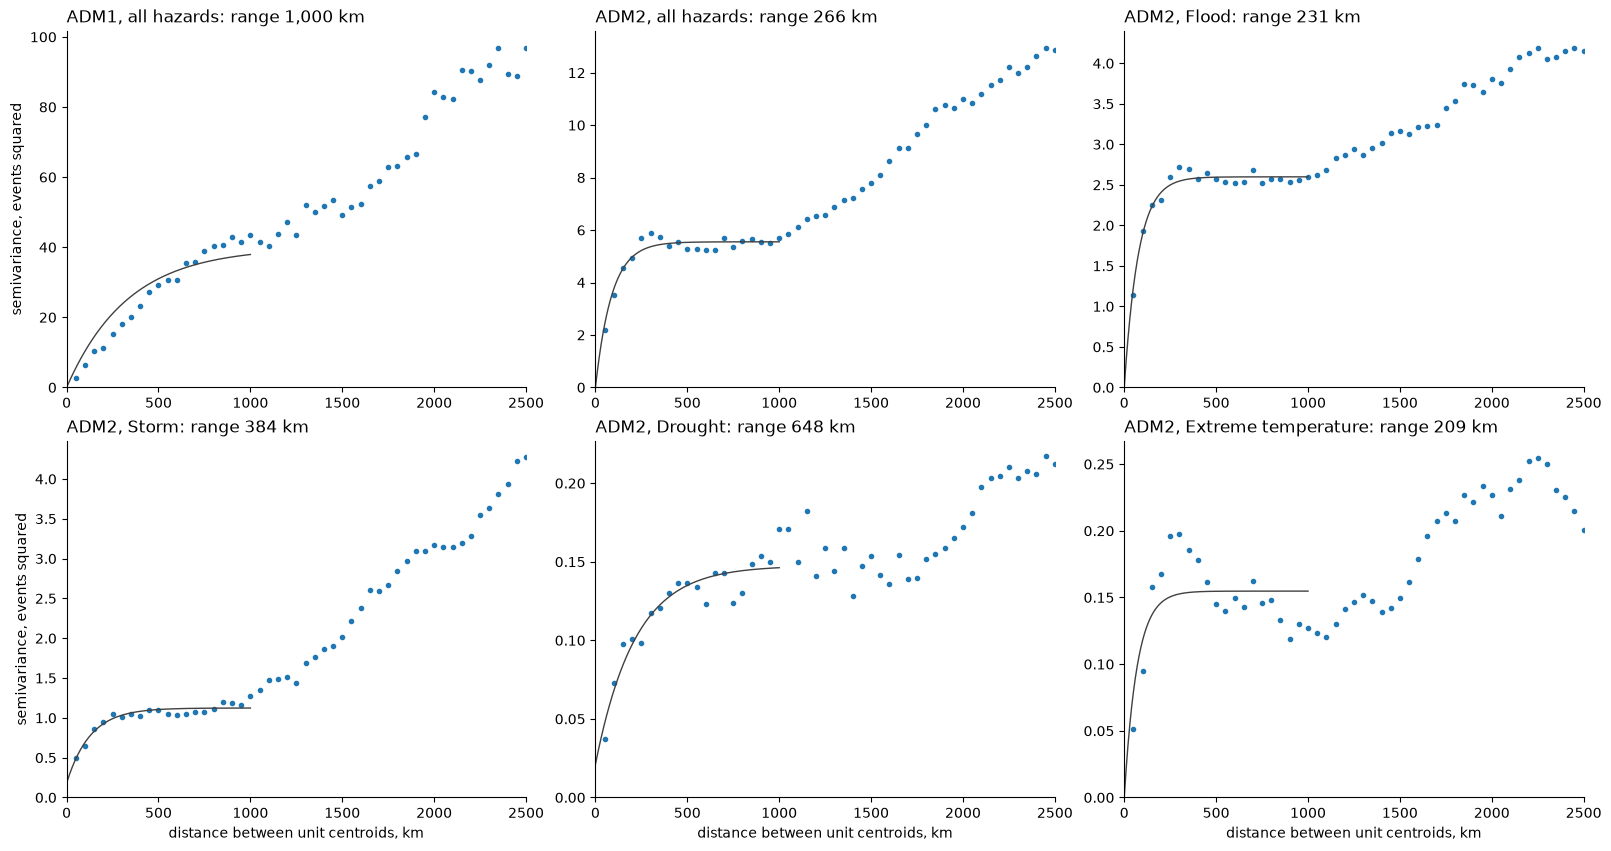

In [24]:
fit_lags = np.linspace(0.0, FIT_MAX_LAG_KM, 200)

figure, axes = plt.subplots(2, 3, figsize=(16, 8.4))

for axis, (title, (experimental, short_range)) in zip(axes.ravel(), variograms.items(), strict=True):
    effective_range, sill, nugget = short_range.parameters
    axis.plot(experimental.bins,
              experimental.experimental,
              "o",
              markersize=3)
    axis.plot(fit_lags,
              short_range.fitted_model(fit_lags),
              color="0.25",
              linewidth=1.0)
    axis.set_xlim(0, MAX_LAG_KM)
    axis.set_ylim(bottom=0)
    axis.set_title(f"{title}: range {effective_range:,.0f} km", loc="left")

for axis in axes[-1]:
    axis.set_xlabel("distance between unit centroids, km")
for axis in axes[:, 0]:
    axis.set_ylabel("semivariance, events squared")

plt.show()

The ADM2 variograms have two structures. The first rises from near zero to a plateau within a few hundred kilometers, with effective ranges of 266 km over all hazards, 231 km for floods and 384 km for storms, and holds flat to about 1,000 km. Beyond 1,000 km the semivariance climbs again without a sill, which is the difference between regions and countries in how many events they record. Droughts give a longer range, 648 km, and the extreme-temperature field is too sparse to fit. ADM1 units are too large to resolve the first structure: the ADM1 curve climbs steadily, and its fitted range sits at the 1,000 km fitting limit.

Pooling every year mixes two things. Units named by the same event share counts, which is the footprint, and neighboring units also share a hazard rate. This variogram cannot separate the two, but its range bounds the footprint's: on the order of 250 to 400 km for floods and storms, in line with the connectivity and distance checks above.

### Splitting the variogram into footprint and rate

A unit's count is the sum of one indicator per event, $N_u = \sum_e z_{ue}$, so for every pair
$$(N_u - N_v)^2 = \sum_e (z_{ue} - z_{ve})^2 + \sum_{e \ne e'} (z_{ue} - z_{ve})(z_{ue'} - z_{ve'}).$$
The first sum is the per-event variograms added up: it is small for nearby pairs only when single events name neighbors together, the footprint. The second is what different events share: it grows with distance when some places are hit more often than others, the rate. The pooled variogram is the sum of the two parts.

The field has to hold every unit, including those no event names, or the units in it are conditioned on being hit. Every GADM unit at the level is in its country's field, and it is named by an event when its representative point lies in a GAUL unit the event names. Each country and level is one field, so both sums run over the same unit pairs, and every variogram is scikit-gstat's over the GADM unit centroids.

In [29]:
gadm_units = gpd.GeoDataFrame(
    pd.concat(
        [
            load_units_in_country(iso, level, DATA_DIR).assign(ISO=iso)
            for iso in tqdm(sorted(reports["ISO"].dropna().unique()), desc="GADM units")
            for level in (1, 2)
        ],
        ignore_index=True,
    )
).to_crs(EQUAL_AREA_CRS)

gadm_points = gadm_units[["ISO", "admin_level"]].set_geometry(gadm_units.representative_point())
containing = gpd.sjoin(gadm_points,
                       units[["admin_level", "geometry"]].reset_index(names="unit_index"),
                       predicate="within")
containing = containing[containing["admin_level_left"] == containing["admin_level_right"]]
gadm_units["unit_index"] = containing.groupby(level=0)["unit_index"].first().reindex(gadm_units.index)

gadm_lon_lat = gadm_units.centroid.to_crs("EPSG:4326")
gadm_longitude, gadm_latitude = np.radians(gadm_lon_lat.x.to_numpy()), np.radians(gadm_lon_lat.y.to_numpy())
gadm_on_sphere = EARTH_RADIUS_KM * np.column_stack([np.cos(gadm_latitude) * np.cos(gadm_longitude),
                                                    np.cos(gadm_latitude) * np.sin(gadm_longitude),
                                                    np.sin(gadm_latitude)])

matched_gaul = set(gadm_units["unit_index"].dropna().astype(int))
pd.DataFrame({
    f"ADM{level}": {
        "GADM units": int((gadm_units["admin_level"] == level).sum()),
        "GADM units inside a named GAUL unit": int(gadm_units.loc[gadm_units["admin_level"] == level, "unit_index"].notna().sum()),
        "named GAUL units": int((units["admin_level"] == level).sum()),
        "named GAUL units holding a GADM point": len(matched_gaul & set(units.index[units["admin_level"] == level])),
    }
    for level in (1, 2)
})

GADM units:   0%|          | 0/206 [00:00<?, ?it/s]

,ADM1,ADM2
GADM units,3455,46847
GADM units inside a named GAUL unit,3169,12136
named GAUL units,2845,7613
named GAUL units holding a GADM point,2614,6941


In [30]:
UPPER_LAG_EDGES_KM = np.arange(LAG_WIDTH_KM, MAX_LAG_KM + LAG_WIDTH_KM, LAG_WIDTH_KM)
SPLIT_FIELDS = {
    "ADM2, all hazards": (2, None),
    "ADM2, Flood": (2, "Flood"),
    "ADM2, Storm": (2, "Storm"),
    "ADM1, all hazards": (1, None),
}


def semivariance_sum(space, values):
    """Half the summed squared difference of ``values`` over the unit pairs in each lag, and the pair count."""
    variogram = skgstat.Variogram(space,
                                  values,
                                  bin_func=UPPER_LAG_EDGES_KM,
                                  fit_method="manual",
                                  fit_range=1.0,
                                  fit_sill=1.0)

    return np.nan_to_num(variogram.experimental) * variogram.bin_count, variogram.bin_count


def split_variogram(level, hazard):
    """The pooled variogram of event counts over every GADM unit and its per-event part, over pairs inside each country."""
    at_level = reports[reports["admin_level"] == level]
    if hazard is not None:
        at_level = at_level[at_level["Disaster Type"] == hazard]

    pooled = np.zeros(len(UPPER_LAG_EDGES_KM))
    per_event = np.zeros(len(UPPER_LAG_EDGES_KM))
    pairs = np.zeros(len(UPPER_LAG_EDGES_KM))

    for iso, in_country in tqdm(at_level.groupby("ISO"), desc=f"ADM{level} {hazard or 'all'}"):
        field = gadm_units[(gadm_units["ISO"] == iso) & (gadm_units["admin_level"] == level)]
        if len(field) < 2:
            continue

        space = skgstat.MetricSpace(gadm_on_sphere[field.index], max_dist=MAX_LAG_KM)
        gaul_unit = field["unit_index"].to_numpy()
        indicators = [np.isin(gaul_unit, event["unit_index"]).astype(float) for _, event in in_country.groupby("DisNo.")]

        summed, counted = semivariance_sum(space, np.sum(indicators, axis=0))
        pooled += summed
        pairs += counted
        for indicator in indicators:
            if 0.0 < indicator.mean() < 1.0:
                per_event += semivariance_sum(space, indicator)[0]

    with np.errstate(invalid="ignore", divide="ignore"):
        return pooled / pairs, per_event / pairs


split_variograms = {name: split_variogram(level, hazard) for name, (level, hazard) in SPLIT_FIELDS.items()}

ADM2 all:   0%|          | 0/177 [00:00<?, ?it/s]

ADM2 Flood:   0%|          | 0/147 [00:00<?, ?it/s]

ADM2 Storm:   0%|          | 0/126 [00:00<?, ?it/s]

ADM1 all:   0%|          | 0/202 [00:00<?, ?it/s]

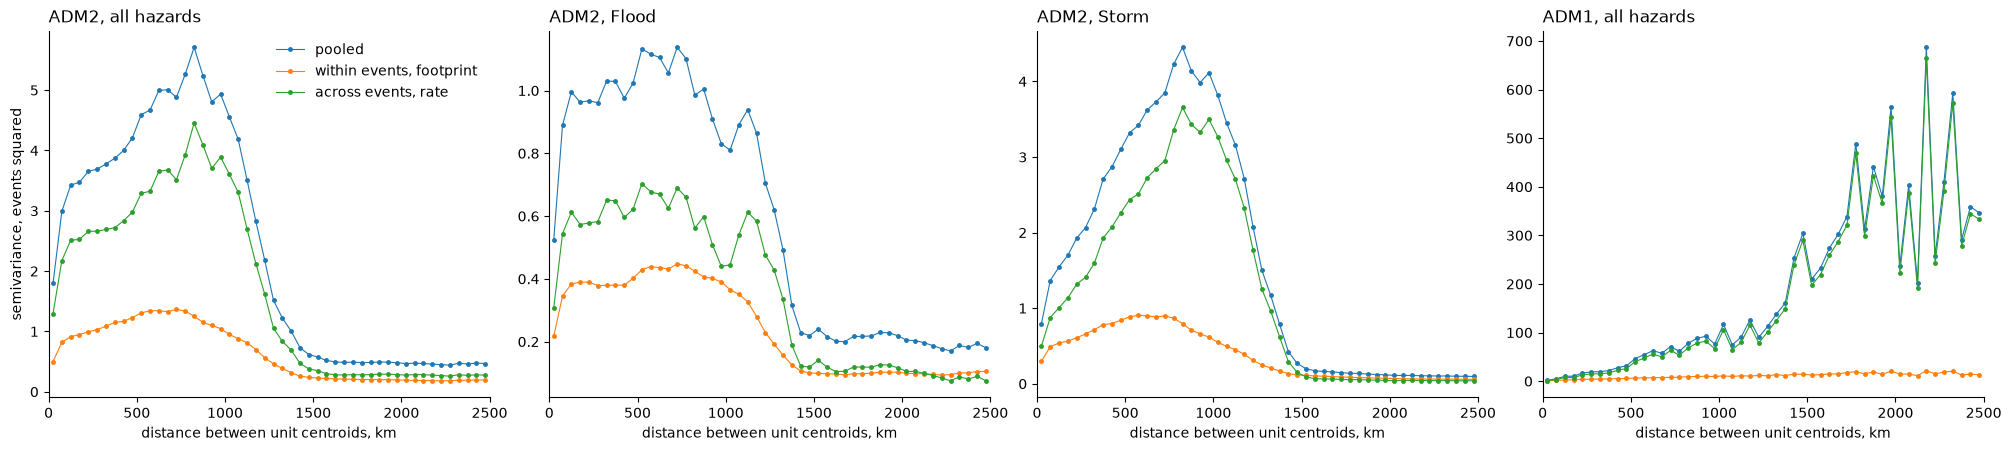

In [31]:
lag_centers = UPPER_LAG_EDGES_KM - LAG_WIDTH_KM / 2

figure, axes = plt.subplots(1, len(split_variograms), figsize=(5.0 * len(split_variograms), 4.4))

for axis, (title, (pooled, per_event)) in zip(axes, split_variograms.items(), strict=True):
    for curve, label in ((pooled, "pooled"), (per_event, "within events, footprint"), (pooled - per_event, "across events, rate")):
        axis.plot(lag_centers,
                  curve,
                  "o-",
                  markersize=2.5,
                  linewidth=0.8,
                  label=label)
    axis.set_xlim(0, MAX_LAG_KM)
    axis.set_xlabel("distance between unit centroids, km")
    axis.set_title(title, loc="left")
axes[0].set_ylabel("semivariance, events squared")
axes[0].legend(frameon=False)

plt.show()

Each part is read by how it rises with distance. If events landed without regard to distance, the within-event part would sit at one level at every lag, so its rise from short to long lags is the footprint, and the distance where it levels off is the footprint's range. The across-event part rises when some places are hit more often than others. With every GADM unit in the field, both parts are positive at every lag.

Within countries at ADM2, the within-event part for floods rises from 0.22 at the shortest lag to about 0.38 by 125 km and holds there, so flood footprints span about 100 to 150 km of ADM2 units. For storms it keeps rising to about 0.9 near 575 km. Over the first 500 km the within-event part carries about 30% of the pooled rise over all ADM2 hazards, 37% for floods and 23% for storms.

Beyond a few hundred kilometers the shapes are composition. Each lag pools pairs from every country, weighted by pair count, and the five countries with the most ADM2 units, Brazil, the United States, Romania, Mexico and Russia, hold about three quarters of the pairs. The peak near 800 km and the collapse past 1,200 km follow which of them have pairs at each distance and how often their units are named.

### Across borders, at ADM1

EM-DAT files one physical event once per country it hits, under a shared `YYYY-NNNN` prefix. Here every GADM ADM1 unit is one global field, so pairs across borders count, and the footprint part is computed twice: once with each country's record as an event, as above, and once with the records of one physical event joined. The pooled variogram is the same for both, and the difference between the two footprint parts is co-naming across borders. Each per-event variogram runs over the units within the largest lag of the event's named units, which holds every pair that event can split.

In [33]:
adm1_reports = reports[reports["admin_level"] == 1].assign(physical_event=reports["DisNo."].str.slice(0, 9))
adm1_field = gadm_units[gadm_units["admin_level"] == 1]
adm1_points = gadm_on_sphere[adm1_field.index]
adm1_gaul = adm1_field["unit_index"].to_numpy()
adm1_tree = cKDTree(adm1_points)


def footprint_sum(event_key):
    """Summed per-event semivariance over the global ADM1 field, with events identified by ``event_key``."""
    summed = np.zeros(len(UPPER_LAG_EDGES_KM))

    for _, event in tqdm(adm1_reports.groupby(event_key), desc=event_key):
        named = np.isin(adm1_gaul, event["unit_index"])
        if not named.any():
            continue

        nearby = np.unique(np.concatenate(adm1_tree.query_ball_point(adm1_points[named], r=MAX_LAG_KM)))
        if named[nearby].all():
            continue

        space = skgstat.MetricSpace(adm1_points[nearby], max_dist=MAX_LAG_KM)
        summed += semivariance_sum(space, named[nearby].astype(float))[0]

    return summed


adm1_counts = np.sum([np.isin(adm1_gaul, event["unit_index"]) for _, event in adm1_reports.groupby("DisNo.")], axis=0)
adm1_pooled_sum, adm1_pairs = semivariance_sum(skgstat.MetricSpace(adm1_points, max_dist=MAX_LAG_KM), adm1_counts.astype(float))

with np.errstate(invalid="ignore", divide="ignore"):
    cross_border = {
        "pooled": adm1_pooled_sum / adm1_pairs,
        "footprint, country records": footprint_sum("DisNo.") / adm1_pairs,
        "footprint, physical events": footprint_sum("physical_event") / adm1_pairs,
    }

adm1_reports[["DisNo.", "physical_event"]].nunique()

DisNo.:   0%|          | 0/4596 [00:00<?, ?it/s]

physical_event:   0%|          | 0/3981 [00:00<?, ?it/s]

DisNo.            4596
physical_event    3981
dtype: int64

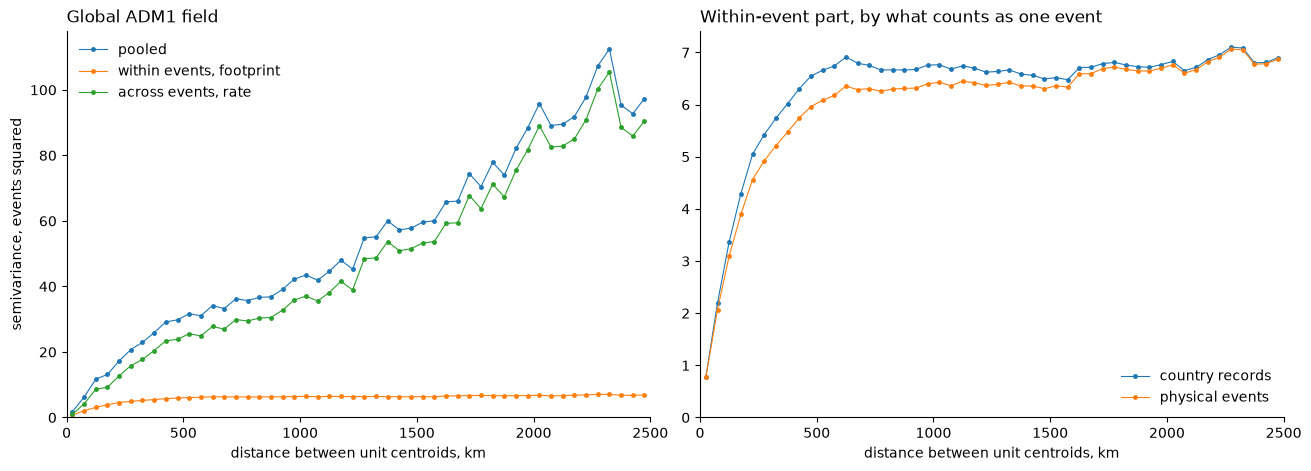

In [35]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))

within_physical = cross_border["footprint, physical events"]
panels = {
    "Global ADM1 field": {
        "pooled": cross_border["pooled"],
        "within events, footprint": within_physical,
        "across events, rate": cross_border["pooled"] - within_physical,
    },
    "Within-event part, by what counts as one event": {
        "country records": cross_border["footprint, country records"],
        "physical events": within_physical,
    },
}

for axis, (title, curves) in zip(axes, panels.items(), strict=True):
    for label, curve in curves.items():
        axis.plot(lag_centers,
                  curve,
                  "o-",
                  markersize=2.5,
                  linewidth=0.8,
                  label=label)
    axis.set_xlim(0, MAX_LAG_KM)
    axis.set_ylim(bottom=0)
    axis.set_xlabel("distance between unit centroids, km")
    axis.set_title(title, loc="left")
    axis.legend(frameon=False)
axes[0].set_ylabel("semivariance, events squared")

plt.show()

In one global field the within-event part rises from 0.77 at the shortest lag to a plateau near 6.3 by about 600 km, with half of that rise done by 125 km, so ADM1 footprints reach about 500 to 600 km. The across-event part keeps rising to 2,500 km without a sill, which is the difference between regions in how often they are hit. Over the first 500 km the within-event part carries about a fifth of the pooled rise, 5.2 of 28.

Joining the country records of one physical event lowers the within-event part by 0.2 to 0.6 between 100 and 1,500 km, at most about 8%, because units on either side of a border named by the same storm or flood are no longer split by it. Of 3,981 physical events reported at ADM1, 331 span more than one country, so co-naming across borders is real but small next to co-naming inside a country.

## Does footprint size depend on the hazard?

Every geocoded event, single-unit ones included, with the number of units it names and their total area, by hazard type and reporting level.

In [12]:
MIN_EVENTS = 30

reports["area_km2"] = units["area_km2"].to_numpy()[reports["unit_index"]]
events = (
    reports.groupby(["DisNo.", "ISO", "admin_level", "Disaster Type"])
    .agg(units=("unit_index", "size"), area_km2=("area_km2", "sum"))
    .reset_index()
)
events["level"] = "ADM" + events["admin_level"].astype(str)

hazard_sizes = events.groupby(["level", "Disaster Type"]).agg(
    events=("units", "size"),
    single_unit=("units", lambda units: (units == 1).mean()),
    median_units=("units", "median"),
    units_90=("units", lambda units: units.quantile(0.9)),
    median_area=("area_km2", "median"),
    area_90=("area_km2", lambda area: area.quantile(0.9)),
)
hazard_sizes = hazard_sizes[hazard_sizes["events"] >= MIN_EVENTS].rename(
    columns={"single_unit": "share naming one unit",
             "median_units": "units, median",
             "units_90": "units, 90%",
             "median_area": "area km2, median",
             "area_90": "area km2, 90%"}
)
hazard_sizes.round({"share naming one unit": 2, "units, median": 0, "units, 90%": 0}).astype({"area km2, median": int, "area km2, 90%": int})

events  share naming one unit  units, median  \
level Disaster Type                                                       
ADM1  Drought                 285                   0.14           5.00   
      Extreme temperature     331                   0.18           6.00   
      Flood                  2020                   0.32           3.00   
      Mass movement (wet)     111                   0.80           1.00   
      Storm                  1710                   0.31           3.00   
      Wildfire                149                   0.41           2.00   
ADM2  Drought                 108                   0.31           4.00   
      Extreme temperature     112                   0.47           2.00   
      Flood                  2553                   0.40           2.00   
      Mass movement (wet)     457                   0.81           1.00   
      Storm                  1136                   0.42           2.00   
      Wildfire                165                   0.50           1.00   

                           units, 90%  area km2, median  area km2, 90%  
level Disaster Type                                                     
ADM1  Drought                   14.00            244186        1548710  
      Extreme temperature       22.00            137238        1092073  
      Flood                     10.00             76404         817397  
      Mass movement (wet)        2.00             36075         409439  
      Storm                     11.00             84092        1261892  
      Wildfire                   6.00            200401        1364899  
ADM2  Drought                   18.00             21256         246786  
      Extreme temperature        9.00              6939          52932  
      Flood                     10.00              7355          62516  
      Mass movement (wet)        2.00              3436          31358  
      Storm                      9.00              6944          42771  
      Wildfire                   6.00             10582          67647

Footprint size depends on the hazard. At ADM2 a drought names a median 21,000 km2 against about 7,000 km2 for a flood or storm and 3,400 km2 for a wet mass movement, and the ADM1 record keeps the same order. Wet mass movements name a single unit 80% of the time, droughts 14% at ADM1 and 31% at ADM2. Since the hazards also differ in where they strike, the size of a named set carries information about location when hazards are pooled. Within one hazard the coarsening can still be close to random.

### Footprint size as a share of the country

A count of units named depends on how finely a country is divided, which varies from a handful of ADM2 units to thousands. Divided by the GADM ADM2 units the country holds, it becomes the share of the country an event names, comparable across countries and with a simulated map. Events reported at ADM2, by hazard class: climatological for droughts, extreme temperatures and wildfires, hydrometeorological for floods, storms and wet mass movements. GAUL divides some countries more finely than GADM, so a share can pass 1.

In [4]:
HAZARD_CLASSES = {
    "Drought": "Climatological",
    "Extreme temperature": "Climatological",
    "Wildfire": "Climatological",
    "Flood": "Hydrometeorological",
    "Storm": "Hydrometeorological",
    "Mass movement (wet)": "Hydrometeorological",
}

country_adm2_units = pd.Series(
    {iso: len(load_units_in_country(iso, 2, DATA_DIR)) for iso in tqdm(sorted(reports["ISO"].dropna().unique()), desc="GADM ADM2 units")},
    name="country units",
)
adm2_events = (
    reports[reports["admin_level"] == 2]
    .groupby(["DisNo.", "ISO", "Disaster Type"])["unit"].nunique().rename("units").reset_index()
    .join(country_adm2_units, on="ISO")
    .query("`country units` > 0")
    .assign(**{"class": lambda table: table["Disaster Type"].map(HAZARD_CLASSES),
               "share of country": lambda table: table["units"] / table["country units"]})
)

adm2_events.groupby("class").agg(
    events=("units", "size"),
    naming_one_unit=("units", lambda units: (units == 1).mean()),
    units_median=("units", "median"),
    units_90=("units", lambda units: units.quantile(0.9)),
    share_median=("share of country", "median"),
    share_75=("share of country", lambda share: share.quantile(0.75)),
    share_90=("share of country", lambda share: share.quantile(0.9)),
    share_99=("share of country", lambda share: share.quantile(0.99)),
    country_units_median=("country units", "median"),
).T.round(3)

GADM ADM2 units:   0%|          | 0/206 [00:00<?, ?it/s]

class,Climatological,Hydrometeorological
events,376.00,4084.00
naming_one_unit,0.44,0.45
units_median,2.00,2.00
units_90,10.00,9.00
share_median,0.01,0.01
share_75,0.05,0.03
share_90,0.14,0.08
share_99,0.71,0.46
country_units_median,240.00,300.00


In units the two classes look alike, a median of 2 and a 90th percentile of 9 or 10, but the events fall in countries with a median of 240 to 300 ADM2 units, so as a share of the country they are small. The median event names 1% of its country's ADM2 units. At the 90th percentile a climatological event names 14% and a hydrometeorological one 8%, and at the 99th 71% and 46%. A country of the simulated map holds 20 ADM2 units, so calibrating footprints to the count of units named, as 09 and 10 do, makes them five to ten times too large as a share of the country.

## What the record shows

Events are footprints. The units one event names are connected two to three times as often as a random set of the same size at ADM1 and eight times or more at ADM2, and at ADM2 their nearest named neighbor is a fifth to three fifths as far away. Splitting the variogram of event counts separates the footprint from the rate: the within-event part levels off near 125 km for ADM2 floods, near 575 km for ADM2 storms and near 600 km in a global ADM1 field, and over the first 500 km it carries a fifth to two fifths of the rise in the pooled variogram. The rest is places being hit more often than others, which keeps rising past 2,500 km. Linking an event's country records across borders changes the footprint part by under a tenth. Footprints are not single connected blobs either: most ADM2 events of six or more units come in several pieces, part of which is the graph's gaps and part separate hits, so a footprint model needs imperfect naming or several patches per event. Footprint size depends on the hazard, so a model that pools hazards should let the footprint distribution depend on hazard type.

The contiguity checks use only the units the record ever names, which for the United States is 1,083 of the 3,148 counties GADM holds, while the split variograms use every GADM unit. Distances are between centroids.